# Model B, B1 — crossing style and state-dependent stops (Oct 30, 2026) — EXPLORATORY

**Spec (given before results; Model B log entry 1, `results/model_b_log.md`):**

TASK: Model B, version B1 (EXPLORATORY). Fits on G-train only; simulations on the usual
L3/L5 designs. Never load Ring/CT. Do not change the frozen presets (L1, final, L1_M3, L0,
APEM): new code paths only, and the old presets must stay bit-identical.
Start results/model_b_log.md: one dated entry per Model B version, with its exact spec. B1 is entry 1.

STATES (causal: what a simulator knows at that moment), per moving player:
- C = crossing attempt: the player has left an end band (|s| >= 0.9; old CL |k| >= 9),
  has not reversed since, and has not yet reached an end band.
- E = elsewhere: first trip (no end band reached yet), outbound after a reversal, or
  in_band (inside an end band but not at the wall).
- At the wall: no stops (as before).

All probabilities use the F1 convention: per-step stop chance = stops / counted moving
steps; resume chance per tick = resumes / halted ticks.

0. DATA CHECK FIRST (G-train, same spells as P17 F1b): do halts inside crossings end faster?
   - Label each mid-round halt by the state at its start (C or E). Per interface: resume
     chance per tick q_C and q_E (censoring as in P17), with group-bootstrap 95% CIs
     (1,000, stratified, seed 573), plus a KM figure of halt duration by state
     (results/figures/pB1_halts_by_state.png).
   - RULE (fixed now): if the q_C and q_E CIs are disjoint in >= 2 of the 3 interfaces,
     B1 uses separate resume chances by state; otherwise one resume chance (L1's). Report which.
1. B1 PARAMETERS (G-train, per interface: lab v09, old CL, CC), with CIs as above:
   - pi, rho: beta-binomial smooth share and overdispersion (already in pB0b_crossing_style.csv; reuse).
   - q_sg: stop chance per step in non-smooth completed crossings (pB0b).
   - q_E: stop chance per step in state E (new: stops / counted steps over first trip +
     outbound after a reversal + in_band).
   - resume: per step 0's rule.
   - Save as results/tables/pB1_params.csv.
2. SIMULATOR (preset "B1"; base = L1 with F1-F3: M2' per bin, lam_start, coin flip; no L1b, no L3):
   - Player trait: each simulated player draws U_i ~ Uniform(0,1) once per group copy per
     replicate. In each round, its smooth propensity is p_i = Beta quantile at U_i, with
     that round's interface (a = pi(1-rho)/rho, b = (1-pi)(1-rho)/rho).
   - When a player enters state C, draw the crossing's style: smooth with probability
     p_i, else stop-and-go. Smooth -> stop chance 0 in C; stop-and-go -> q_sg per step.
   - In state E: stop chance q_E per step.
   - Resume per tick: q_C or q_E by the state at the halt start (or one value, per the rule).
   - Tests: all old presets bit-identical; with p_i = 0, q_sg = q_E = L1's per-step stop
     chance and a single resume chance, B1 equals L1 exactly; unit tests for the state
     labels and the style draw.
3. BUILD CHECK (recovery): simulate B1 on the G6train design, R = 2, seed 573. Re-estimate
   pi, rho, q_sg, q_E and the resume chance(s) with the same code as steps 0-1.
   PASS: each within its 95% CI. If anything fails: diagnose and propose; don't fix by changing numbers.
4. RUN SCRIPTS: add preset "B1" (seed 6001, registered) to scripts/p24_main.py and to
   p24_checks.py. Report B1 next to final and L1, labeled EXPLORATORY; no triggers.
   Smoke-test with R = 2, then delete the outputs.


## Choices the spec leaves open

Fixed before any B1 number was looked at; data side in `src/slider/model_b1.py`, simulator in `sim.py` (motion "B1", a new code path).

- **States of a halt:** the halts are P17's (F1b) halted time, found again row by row (`model_b1.seat_halts`, checked against `motion.motion_table` below). A halt gets the state of the own-step row that starts it. A reversal counts for that row if its first step is after the phase's first row and at or before the row. So a halt right after the step that confirms a reversal is E.
- **Halted ticks** n = max(1, round(duration / dt)) (as `halts.add_ticks`, P25). Resume chance per tick = resumes / halted ticks; reversal, probe, unresolved and round end are censored (P17).
- **Rule:** the C and E CIs are compared per interface; pooled rows are descriptive only.
- **q_E** = stops / counted steps over first_trip, outbound after a reversal and in_band (B0's step labels: E = not (outbound and reversed = 0)).
- **pi, rho, q_sg** are read from `pB0b_crossing_style.csv` (B0b; CIs as there).
- **Single resume chance (if the rule says so):** L1's, lam_resume (P17) times the round's dt, as L1 uses it.
- **Simulator, state C** starts at the tick whose step leaves an end band (|k| from >= 9 to < 9, the tick detector). It ends when the player enters an end band, or when the detector confirms a reversal whose first step of k came after that tick (the turn that leaves the wall or the band is not one). The style is drawn at entry (smooth with p_i). A player stays in the same crossing, with the same style, while halted. E is every other moving or halted player; at the wall there are no stops.
- **Per-step stop chance** in the simulator is the drawn chance itself (stops / moving steps; L1's F1 convention).
- **Trait:** U_i ~ Uniform(0, 1) per seat of each group copy (all rounds of the copy, every interface it plays). p_i = the Beta(a, b) quantile at U_i with the round's interface (a = pi (1 - rho) / rho, b = (1 - pi)(1 - rho) / rho). If p_i is 0 or 1, no style is drawn, so p_i = 0 with q_sg = q_E = L1's chance and one resume chance is L1 exactly.
- **Random streams:** the U values come from a stream spawned after the round streams (like L3's u). Inside a round, B1 draws its styles only when a player enters C with 0 < p_i < 1; every other draw is L1's.
- **Recovery:** players are (group copy, seat). pi and rho are refit on the simulated players with >= 3 completed crossings. PASS = each re-estimate inside the step-1 95% CI, per interface. The single L1 resume chance is checked as lam_resume (resumes / halted seconds, P17's estimator) against P17's CI.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slider import config, model_b1, motion, stop_states
from slider import halts as halts_mod
from slider import slider_logs as sl
from slider.stats import kaplan_meier

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior")                  # roles={"train"}: G-train only, no G-val, Ring or CT
assert set(table["role"]) == {"train"}
halts = model_b1.halt_table(runs)
p17 = halts_mod.add_ticks(motion.motion_table(runs)[1])
key = ["file", "wave", "player", "start"]
a, b = halts.sort_values(key).reset_index(drop=True), p17.sort_values(key).reset_index(drop=True)
assert len(a) == len(b) and np.allclose(a["duration"], b["duration"]) and (a["exit"] == b["exit"]).all()
print(len(runs), "rounds,", len(halts), "halts (the P17 F1b halts, same durations and exits)")

244 rounds, 32263 halts (the P17 F1b halts, same durations and exits)


## Step 0: resume chance per tick by state at the halt start (95% CI: 1,000 stratified group resamples, seed 573)

In [2]:
def resume_rows(d, name):
    x = d.assign(**{f"{k}_{s}": (d[k] if k == "n" else d["event"]) * (d["state"] == s) for s in "CE" for k in ["n", "e"]})
    low, high = motion.boot_ratios(x, [("e_C", "n_C"), ("e_E", "n_E"), ("event", "n")])
    out = []
    for i, state in enumerate(["C", "E", "all"]):
        y = d if state == "all" else d[d["state"] == state]
        out.append({"interface": "pooled" if name == "shared" else name, "state": state, "halts": len(y),
                    "resumes": int(y["event"].sum()), "halted_ticks": int(y["n"].sum()),
                    "q_resume": y["event"].sum() / y["n"].sum(), "ci_low": low[i], "ci_high": high[i],
                    "share_of_halts": len(y) / len(d)})
    return out


step0 = pd.DataFrame([r for name, d in motion.by_interface(halts) for r in resume_rows(d, name)])
step0.to_csv(config.PB1_HALTS, index=False)
step0.round(4)

,interface,state,halts,resumes,halted_ticks,q_resume,ci_low,ci_high,share_of_halts
0,lab_v09,C,7085,6398,34630,0.1848,0.1365,0.2368,0.5698
1,lab_v09,E,5349,4875,30214,0.1613,0.1488,0.1793,0.4302
2,lab_v09,all,12434,11273,64844,0.1738,0.1447,0.2025,1.0000
3,old_cl,C,1145,1067,5931,0.1799,0.1704,0.2004,0.3203
4,old_cl,E,2430,2200,12897,0.1706,0.1497,0.2246,0.6797
5,old_cl,all,3575,3267,18828,0.1735,0.1560,0.2163,1.0000
6,cc,C,9235,8771,73206,0.1198,0.1028,0.1350,0.5682
7,cc,E,7019,6548,113296,0.0578,0.0491,0.0712,0.4318
8,cc,all,16254,15319,186502,0.0821,0.0704,0.0971,1.0000
9,pooled,C,17465,16236,113767,0.1427,0.1239,0.1596,0.5413


In [3]:
ci = step0.set_index(["interface", "state"])
disjoint = {}
for name in motion.INTERFACES:
    c, e = ci.loc[(name, "C")], ci.loc[(name, "E")]
    disjoint[name] = bool(c["ci_high"] < e["ci_low"] or e["ci_high"] < c["ci_low"])
    print(f"{name:8s} q_C {c['q_resume']:.4f} [{c['ci_low']:.4f}, {c['ci_high']:.4f}]   "
          f"q_E {e['q_resume']:.4f} [{e['ci_low']:.4f}, {e['ci_high']:.4f}]   disjoint: {disjoint[name]}")
SEPARATE = sum(disjoint.values()) >= 2
print(f"RULE: disjoint in {sum(disjoint.values())} of 3 ->",
      "B1 uses separate resume chances by state" if SEPARATE else "B1 uses one resume chance (L1's)")

lab_v09  q_C 0.1848 [0.1365, 0.2368]   q_E 0.1613 [0.1488, 0.1793]   disjoint: False
old_cl   q_C 0.1799 [0.1704, 0.2004]   q_E 0.1706 [0.1497, 0.2246]   disjoint: False
cc       q_C 0.1198 [0.1028, 0.1350]   q_E 0.0578 [0.0491, 0.0712]   disjoint: True
RULE: disjoint in 1 of 3 -> B1 uses one resume chance (L1's)


**How to read it.** q_resume is the chance per halted tick that a halt ends in a resume (other exits censored), for halts that start in a crossing attempt (C) or elsewhere (E); `share_of_halts` is the state's share of the interface's halts. The rule compares the C and E CIs per interface.

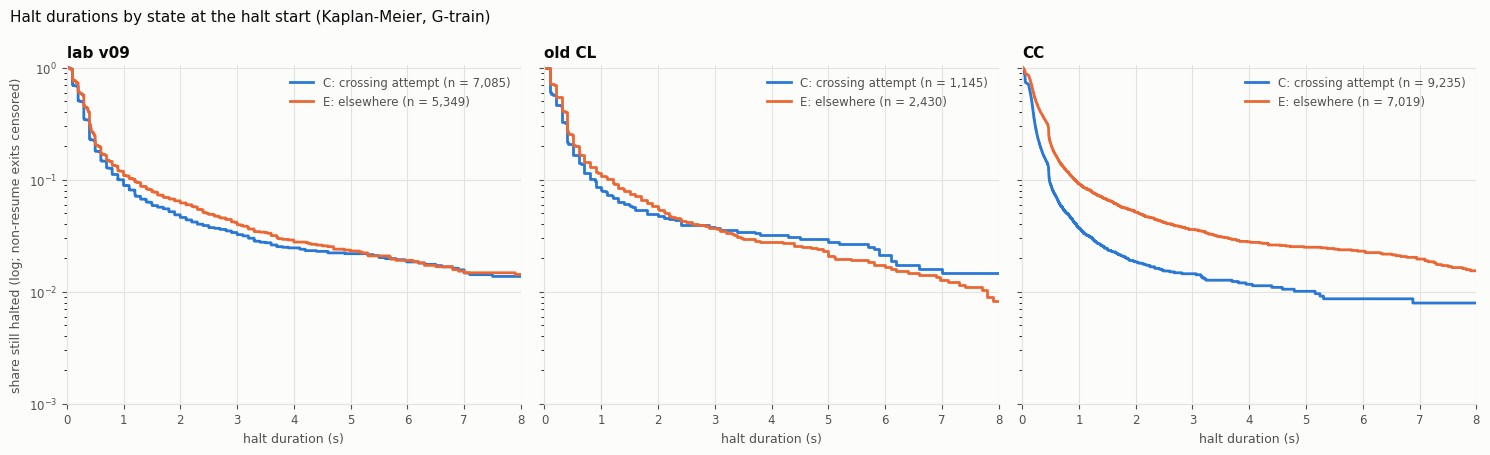

In [4]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"C": "#2a78d6", "E": "#eb6834"}
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC"}
LABELS = {"C": "C: crossing attempt", "E": "E: elsewhere"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), facecolor=SURFACE, sharey=True)
for ax, name in zip(axes, motion.INTERFACES):
    for state, color in COLORS.items():
        x = halts[(halts["interface"] == name) & (halts["state"] == state)]
        km, _ = kaplan_meier(x["duration"], x["event"])
        ax.step(np.r_[0, km["time"]], np.r_[1, km["survival"]], where="post", color=color, linewidth=2,
                label=f"{LABELS[state]} (n = {len(x):,})")
    ax.set_yscale("log")
    ax.set_xlim(0, 8)
    ax.set_ylim(1e-3, 1.05)
    ax.set_title(NAMES[name], loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_xlabel("halt duration (s)", color=INK_2, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)
    ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper right")
axes[0].set_ylabel("share still halted (log; non-resume exits censored)", color=INK_2, fontsize=9)
fig.suptitle("Halt durations by state at the halt start (Kaplan-Meier, G-train)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(config.PB1_HALTS_FIGURE, dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** Each curve is the share of halts still going after that many seconds (log scale). A curve that falls faster means halts that end sooner. Resume chances per tick are in the table above; on lab v09 and CC the tick differs between rounds, so seconds and ticks do not map one to one.

## Step 1: B1 parameters per interface

In [5]:
steps = model_b1.step_state(stop_states.step_table(runs))
x = steps.assign(n_E=(steps["state"] == "E").astype(int), y_E=steps["stop"] * (steps["state"] == "E"))
b0b = pd.read_csv(config.PB0B_STYLE)
p17_rates = pd.read_csv(config.P17_RATES).set_index(["interface", "rate"])
rows = []
for name in motion.INTERFACES:
    st = x[x["interface"] == name]
    (low,), (high,) = motion.boot_ratios(st, [("y_E", "n_E")])
    bb = b0b[b0b["interface"] == name].set_index("cell")
    for par, cell, unit in [("pi", "pi", "share"), ("rho", "rho", "-"),
                            ("q_sg", "stop chance per step, non-smooth crossings", "per step")]:
        r = bb.loc[cell]
        rows.append({"interface": name, "parameter": par, "estimate": r["estimate"], "ci_low": r["ci_low"],
                     "ci_high": r["ci_high"], "unit": unit, "source": "pB0b_crossing_style.csv"})
    rows.append({"interface": name, "parameter": "q_E", "estimate": st["y_E"].sum() / st["n_E"].sum(), "ci_low": low,
                 "ci_high": high, "unit": "per step", "source": "B0 steps in state E"})
    if SEPARATE:
        for state in "CE":
            r = ci.loc[(name, state)]
            rows.append({"interface": name, "parameter": f"resume_{state}", "estimate": r["q_resume"],
                         "ci_low": r["ci_low"], "ci_high": r["ci_high"], "unit": "per tick", "source": "step 0"})
    else:
        r = p17_rates.loc[(name, "lam_resume")]
        rows.append({"interface": name, "parameter": "lam_resume", "estimate": r["estimate"], "ci_low": r["ci_low"],
                     "ci_high": r["ci_high"], "unit": "per s (x the round's dt, as L1)", "source": "p17_rates.csv (L1)"})
params = pd.DataFrame(rows)
params.to_csv(config.PB1_PARAMS, index=False)
params.round(4)

,interface,parameter,estimate,ci_low,ci_high,unit,source
0,lab_v09,pi,0.4286,0.3814,0.4780,share,pB0b_crossing_style.csv
1,lab_v09,rho,0.1819,0.1034,0.2689,-,pB0b_crossing_style.csv
2,lab_v09,q_sg,0.4663,0.3997,0.5256,per step,pB0b_crossing_style.csv
3,lab_v09,q_E,0.4462,0.4063,0.4834,per step,B0 steps in state E
4,lab_v09,lam_resume,1.7681,1.4773,2.0651,"per s (x the round's dt, as L1)",p17_rates.csv (L1)
5,old_cl,pi,0.2841,0.1667,0.4304,share,pB0b_crossing_style.csv
6,old_cl,rho,0.4000,0.2127,0.4000,-,pB0b_crossing_style.csv
7,old_cl,q_sg,0.1389,0.1121,0.2233,per step,pB0b_crossing_style.csv
8,old_cl,q_E,0.2538,0.2523,0.2547,per step,B0 steps in state E
9,old_cl,lam_resume,1.7356,1.5600,2.1657,"per s (x the round's dt, as L1)",p17_rates.csv (L1)


**How to read it.** The parameters B1 runs on, per interface. pi is the mean smooth propensity, and rho how much players differ in it (0 = all alike). q_sg and q_E are stop chances per moving step in a stop-and-go crossing and in state E (in a smooth crossing it is 0). The resume chance follows the step-0 rule. Old CL has 2 groups and 14 players with >= 3 crossings, so its CIs are crude.

## Step 2: simulator check (preset "B1")

`sim.preset("B1")` = M2' per bin (F2), L1 motion (lam_start, coin flip, L1's resume chance), F3 script, plus the B1 stops (no L1b, no L3). Tests in `tests/test_b1.py`: the five old presets bit-identical (`tests/data/preset_fingerprints.json`, made before the change); B1 with p_i = 0, q_sg = q_E = L1's stop chance = L1 exactly; the halt states on a synthetic path; and simulated C / E states = the estimator's labels (all smooth: no stop in C; q_E = 0: no stop in E), in all three interfaces.

In [6]:
from slider import design, sim

print({name: sim.b1_params(name) for name in motion.INTERFACES})
print({k: v for k, v in sim.preset("B1").items() if k != "rule"}, "rule: M2' per bin")

{'lab_v09': {'pi': 0.4285573865254162, 'rho': 0.1818870951654979, 'q_sg': 0.466315073154134, 'q_E': 0.4461799021452766}, 'old_cl': {'pi': 0.2840868169495913, 'rho': 0.3999516075569687, 'q_sg': 0.1389362912400455, 'q_E': 0.2538192928852029}, 'cc': {'pi': 0.3783371741984311, 'rho': 0.4160880487376764, 'q_sg': 0.4914188392506223, 'q_E': 0.5033425088478175}}
{'motion': 'B1', 'script': True, 'trait': True} rule: M2' per bin


## Step 3: build check — B1 on G6train, R = 2, seed 573

In [7]:
import time

G6 = design.design("G6train")
start = time.time()
rounds = design.simulate_rounds(G6, "B1", R=2, seed=573)
sim_runs = [run for r in range(2) for run in design.copy_runs(G6, rounds, r, 573)]
est, used = model_b1.estimates(sim_runs)
seats_sim, _ = motion.motion_table(sim_runs)
lam = seats_sim.groupby("interface")[["resumes", "halted_s"]].sum()
est["lam_resume"] = lam["resumes"] / lam["halted_s"]
players_sim = used["cross"].groupby(["interface", "file", "player"]).size()
print(len(sim_runs), "rounds |", len(used["steps"]), "counted steps |", len(used["cross"]), "completed crossings |",
      int((players_sim >= 3).sum()), "players with >= 3 |", f"{(time.time() - start) / 60:.1f} min")
est.round(4)

488 rounds | 564061 counted steps | 18703 completed crossings | 538 players with >= 3 | 6.1 min


,pi,rho,q_sg,q_E,resume_C,resume_E,resume_all,lam_resume
interface,,,,,,,,
lab_v09,0.4800,0.1745,0.4481,0.4463,0.1524,0.1568,0.1542,1.7718
old_cl,0.2089,0.1728,0.1730,0.2542,0.1796,0.1766,0.1774,1.7735
cc,0.4356,0.4291,0.4794,0.5059,0.0832,0.0837,0.0834,2.5570


In [8]:
rec = params.merge(est.reset_index().melt(id_vars="interface", var_name="parameter", value_name="re_estimate"),
                   on=["interface", "parameter"], how="left")
rec["pass"] = (rec["re_estimate"] >= rec["ci_low"]) & (rec["re_estimate"] <= rec["ci_high"])
rec = rec[["interface", "parameter", "estimate", "ci_low", "ci_high", "re_estimate", "pass"]].rename(
    columns={"estimate": "true (human fit)"})
rec.to_csv(config.PB1_RECOVERY, index=False)
print(f"PASS {int(rec['pass'].sum())} of {len(rec)}")
rec.round(4)

PASS 12 of 15


,interface,parameter,true (human fit),ci_low,ci_high,re_estimate,pass
0,lab_v09,pi,0.4286,0.3814,0.4780,0.4800,False
1,lab_v09,rho,0.1819,0.1034,0.2689,0.1745,True
2,lab_v09,q_sg,0.4663,0.3997,0.5256,0.4481,True
3,lab_v09,q_E,0.4462,0.4063,0.4834,0.4463,True
4,lab_v09,lam_resume,1.7681,1.4773,2.0651,1.7718,True
5,old_cl,pi,0.2841,0.1667,0.4304,0.2089,True
6,old_cl,rho,0.4000,0.2127,0.4000,0.1728,False
7,old_cl,q_sg,0.1389,0.1121,0.2233,0.1730,True
8,old_cl,q_E,0.2538,0.2523,0.2547,0.2542,True
9,old_cl,lam_resume,1.7356,1.5600,2.1657,1.7735,True


**How to read it.** B1 was simulated with the step-1 values on every G-train round (2 copies), and every parameter was then estimated again from the simulated logs, with the code of steps 0-1. PASS = the re-estimate falls inside the human 95% CI. lam_resume is L1's single resume chance (resumes / halted seconds, as P17).

In [9]:
h_sim = used["halts"]
sim_q = pd.DataFrame([r for name, d in motion.by_interface(h_sim) for r in resume_rows(d, name)])
sim_q[sim_q["interface"] != "pooled"].round(4)

,interface,state,halts,resumes,halted_ticks,q_resume,ci_low,ci_high,share_of_halts
0,lab_v09,C,34917,32641,214216,0.1524,0.1385,0.1652,0.5896
1,lab_v09,E,24304,22423,142975,0.1568,0.1456,0.1672,0.4104
2,lab_v09,all,59221,55064,357191,0.1542,0.1416,0.1659,1.0000
3,old_cl,C,6495,6290,35024,0.1796,0.1767,0.1829,0.2511
4,old_cl,E,19367,18347,103890,0.1766,0.1749,0.1788,0.7489
5,old_cl,all,25862,24637,138914,0.1774,0.1762,0.1787,1.0000
6,cc,C,52668,50287,604304,0.0832,0.0820,0.0844,0.6411
7,cc,E,29487,27846,332625,0.0837,0.0824,0.0849,0.3589
8,cc,all,82155,78133,936929,0.0834,0.0823,0.0844,1.0000


Descriptive: q_C and q_E in the simulated logs. B1 uses one resume chance, so they should be about equal; the human values are in the step-0 table.

## Diagnosis of the misses (descriptive; nothing refit, no number changed)

**(1) pi (lab v09, CC): selection by completion?** pi is fit on completed crossings, but the simulator draws the style when a crossing attempt starts (state C). A stop-and-go attempt takes longer, so a reversal or the round end is more likely to cut it short, and the completed ones over-represent smooth styles. Below, per interface, every outbound C segment (attempt) is classed by its outcome, with the share of attempts with no stop in their C steps. A smooth attempt never stops in C; a stop-and-go one almost always does (q_sg ~ 0.5 per step), unless it is very short. The last column refits pi on **all** attempts with a two-class mixture (smooth: 0 stops; stop-and-go: Binomial(n C steps, q)), pi and q free, by maximum likelihood.

In [10]:
from scipy import optimize, stats


def attempts(steps):
    c = steps[steps["state"] == "C"]
    return c.groupby(["interface", "file", "wave", "player", "segment"]).agg(
        outcome=("outcome", "first"), n=("stop", "size"), stops=("stop", "sum")).reset_index()


def mixture_pi(a):
    def nll(x):
        p, q = 1 / (1 + np.exp(-x))
        like = p * (a["stops"] == 0) + (1 - p) * stats.binom.pmf(a["stops"], a["n"], q)
        return -np.log(like).sum()
    return 1 / (1 + np.exp(-optimize.minimize(nll, [0.0, 0.0], method="Nelder-Mead").x))


def selection_table(steps, who):
    a = attempts(steps)
    out = []
    for name in motion.INTERFACES:
        x = a[a["interface"] == name]
        row = {"data": who, "interface": name, "attempts": len(x)}
        for o in ["completed", "aborted", "censored"]:
            y = x[x["outcome"] == o]
            row[f"{o}: n"], row[f"{o}: no-stop share"] = len(y), (y["stops"] == 0).mean() if len(y) else np.nan
        row["all: no-stop share"] = (x["stops"] == 0).mean()
        row["mixture pi (all attempts)"], row["mixture q"] = mixture_pi(x)
        out.append(row)
    return out


sel = pd.DataFrame(selection_table(steps, "human") + selection_table(used["steps"], "B1 sim"))
sel["true pi (sim input)"] = sel["interface"].map(params[params["parameter"] == "pi"].set_index("interface")["estimate"])
sel.round(3)

,data,interface,attempts,completed: n,completed: no-stop share,aborted: n,aborted: no-stop share,censored: n,censored: no-stop share,all: no-stop share,mixture pi (all attempts),mixture q,true pi (sim input)
0,human,lab_v09,1735,1267,0.440,467,0.105,1,0.000,0.350,0.342,0.477,0.429
1,human,old_cl,178,101,0.238,75,0.000,2,0.000,0.135,0.135,0.141,0.284
2,human,cc,1974,1665,0.431,299,0.040,10,0.000,0.370,0.369,0.501,0.378
3,B1 sim,lab_v09,10411,7379,0.526,2987,0.294,45,0.133,0.458,0.445,0.467,0.429
4,B1 sim,old_cl,1509,592,0.333,840,0.305,77,0.286,0.315,0.253,0.140,0.284
5,B1 sim,cc,13264,10732,0.500,2460,0.143,72,0.153,0.432,0.429,0.488,0.378


**(2) rho (old CL): how precise is the human value?** The human fit uses 14 players from 2 groups, so its group-bootstrap CI has only three distinct resamples (it is [0.213, 0.400], with the estimate on the upper edge). As a check of that width: 1,000 parametric resamples of 14 players with the human pi, rho and each player's own number of crossings, refit by the same code (seed 573).

In [11]:
from slider import model_b

pl = model_b.player_shares(model_b.crossing_table(runs, steps))
pl = pl[pl["interface"] == "old_cl"]
pi0, rho0 = params.set_index(["interface", "parameter"]).loc[[("old_cl", "pi"), ("old_cl", "rho")], "estimate"]
a0, b0 = pi0 * (1 - rho0) / rho0, (1 - pi0) * (1 - rho0) / rho0
rng = np.random.default_rng(573)
fits = np.array([model_b.betabinom_fit(stats.betabinom.rvs(pl["n"], a0, b0, random_state=rng), pl["n"].to_numpy())
                 for _ in range(1000)])
sim_pl = model_b.player_shares(used["cross"])
print(f"old CL: {len(pl)} human players (crossings {pl['n'].sum()}); {int((sim_pl['interface'] == 'old_cl').sum())} simulated players")
print(f"rho refit on 14 players drawn from Beta-binomial(pi = {pi0:.3f}, rho = {rho0:.3f}): "
      f"2.5-97.5% [{np.percentile(fits[:, 1], 2.5):.3f}, {np.percentile(fits[:, 1], 97.5):.3f}], median {np.median(fits[:, 1]):.3f}")

old CL: 14 human players (crossings 101); 28 simulated players
rho refit on 14 players drawn from Beta-binomial(pi = 0.284, rho = 0.400): 2.5-97.5% [0.107, 0.644], median 0.373


**How to read it.** (1) If the B1 simulation's no-stop share is higher among completed attempts than among all attempts, and the mixture pi on all attempts sits near the true input, then pi's miss comes from fitting pi on completed crossings while the simulator draws it per attempt. (2) If 14 players give rho anywhere in a wide range, the old CL miss reflects how few human players the CI rests on.

## Build check verdict (written after the results; no number changed, nothing refit)

**PASS 12 of 15.** All stop and resume chances are recovered (q_sg, q_E, lam_resume in all three interfaces). Misses: pi on lab v09 (0.480 vs. CI [0.381, 0.478]) and CC (0.436 vs. [0.338, 0.422]), and rho on old CL (0.173 vs. [0.213, 0.400]).

**Diagnosis.**
1. *pi, selection by completion.* B1 draws the style per crossing attempt, but pi was fit on completed crossings only. In the B1 simulation, the no-stop share among completed attempts (lab v09 0.53, CC 0.50) is well above the share among all attempts (0.46, 0.43), because stop-and-go attempts are more often cut short by a reversal. The human data show the same gap (completed 0.44 / 0.43 vs. all attempts 0.35 / 0.37), so the human pi (0.429 / 0.378) overstates the per-attempt smooth propensity, and the simulation then adds the selection a second time. A two-class mixture fit on all attempts (smooth: 0 stops; stop-and-go: Binomial(n, q)) comes close to the input on lab v09 (0.445 vs. 0.429) but still sits above it on CC (0.429 vs. 0.378). A likely second selection is that smoother players make more attempts per round, so attempt-weighted shares lean toward them.
2. *rho, old CL.* The human CI rests on 14 players from 2 groups (3 distinct bootstrap resamples; the estimate is its upper edge). 14 players drawn from the fitted beta-binomial give rho refits in [0.107, 0.644], so the simulated 0.173 is consistent with the model. The CI is too narrow, the same kind of old-CL limitation as P25's q_s.

**Proposals (not applied).**
- (a) Fit the style parameters per attempt: a player-level beta-binomial mixture over all crossing attempts (completed, aborted, censored). Each attempt is smooth (0 stops in C) with the player's p_i, or else stop-and-go with Binomial(n C steps, q_sg). pi, rho and q_sg are fit jointly, by player.
- (b) Or calibrate pi by simulation, so that B1's completed-crossing smooth share matches the human one.
- (c) Old CL rho: use a parametric (player-level) CI, or carry old CL rho as a known limitation.